# Практическая работа 2. Базовый анализ агроданных в pandas

Выполнил: Мешков Егор Константинович, группа Д-Э 18-24

**Цель работы:** научиться выполнять базовые операции с табличными данными в `pandas`: первичный обзор данных, выбор столбцов и строк, фильтрация, сортировка, группировка, объединение таблиц, простое кодирование категориальных признаков и визуализация.

## 1. Подготовка среды и исходный датасет.

Откройте Jupyter Notebook или Google Colab и выполните следующую ячейку.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

data = {
    "year":  [
        2022, 2022, 2022, 2022,
        2023, 2023, 2023, 2023,
        2024, 2024
    ],
    "crop":  [
        "wheat", "barley", "corn",  "wheat",
        "wheat", "barley", "corn",  "wheat",
        "wheat", "corn"
    ],
    "yield_t_per_ha": [
        3.2, 2.8, 5.0, 3.0,
        3.5, 2.9, 5.2, 2.7,
        3.3, 5.1
    ],
    "region": [
        "Central", "Central", "Central", "North",
        "South",   "South",   "South",   "North",
        "North",   "South"
    ],
}

df_yield = pd.DataFrame(data)
df_yield

,year,crop,yield_t_per_ha,region
0,2022,wheat,3.2,Central
1,2022,barley,2.8,Central
2,2022,corn,5.0,Central
3,2022,wheat,3.0,North
4,2023,wheat,3.5,South
5,2023,barley,2.9,South
6,2023,corn,5.2,South
7,2023,wheat,2.7,North
8,2024,wheat,3.3,North
9,2024,corn,5.1,South


## 2. Первичный обзор данных

При первом знакомстве с таблицей нужно понять:

* сколько в ней строк и столбцов;
* какие типы данных содержатся в столбцах;
* каковы основные числовые характеристики.

Для этого используются методы `head()`, `info()` и `describe()`.

### Задание 2.1

1. Выведите первые 5 строк таблицы.
2. Посмотрите общую информацию о таблице.
3. Получите статистику по числовым столбцам.

In [2]:
# display выводит каждую таблицу, иначе Colab показывает только последнюю
display(df_yield.head())
df_yield.info()
display(df_yield.describe())

,year,crop,yield_t_per_ha,region
0,2022,wheat,3.2,Central
1,2022,barley,2.8,Central
2,2022,corn,5.0,Central
3,2022,wheat,3.0,North
4,2023,wheat,3.5,South


<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            10 non-null     int64  
 1   crop            10 non-null     str    
 2   yield_t_per_ha  10 non-null     float64
 3   region          10 non-null     str    
dtypes: float64(1), int64(1), str(2)
memory usage: 452.0 bytes


,year,yield_t_per_ha
count,10.000000,10.000000
mean,2022.800000,3.670000
std,0.788811,1.015491
min,2022.000000,2.700000
25%,2022.000000,2.925000
50%,2023.000000,3.250000
75%,2023.000000,4.625000
max,2024.000000,5.200000


## 3. Выбор столбцов и строк

Один столбец выбирается как `df["col"]`, несколько столбцов как `df[["col1", "col2"]]`. Строки можно выбирать по индексу через `loc` и по позиции через `iloc`.

### Задание 2

1. Выберите только столбец `crop`.
2. Выберите только столбцы `year` и `yield_t_per_ha`.

In [3]:
crops = df_yield["crop"]
year_yield = df_yield[["year", "yield_t_per_ha"]]

display(crops)
display(year_yield)

0     wheat
1    barley
2      corn
3     wheat
4     wheat
5    barley
6      corn
7     wheat
8     wheat
9      corn
Name: crop, dtype: str

,year,yield_t_per_ha
0,2022,3.2
1,2022,2.8
2,2022,5.0
3,2022,3.0
4,2023,3.5
5,2023,2.9
6,2023,5.2
7,2023,2.7
8,2024,3.3
9,2024,5.1


### Задание 3

1. Выведите строку с индексом 0.
2. Выведите строки с индексами 2 и 7.

In [4]:
row0 = df_yield.loc[0]
rows_2_7 = df_yield.iloc[[2, 7]]

display(row0)
display(rows_2_7)

year                 2022
crop                wheat
yield_t_per_ha        3.2
region            Central
Name: 0, dtype: object

,year,crop,yield_t_per_ha,region
2,2022,corn,5.0,Central
7,2023,wheat,2.7,North


## 3. Фильтрация данных

### Теория

Фильтрация выполняется через булевы маски. Сложные условия комбинируются операторами `&`, `|` и `~`. Альтернативно можно использовать метод `query()`, где условие записывается строкой.

### Задание 4. Фильтрация через булевы маски

1. Выведите все строки, где культура `wheat`.
2. Выведите строки, где урожайность больше 3.0 т/га.
3. Выведите строки за 2023 год в регионе `South`.

In [5]:
wheat_df = df_yield[df_yield["crop"] == "wheat"]
high_yield = df_yield[df_yield["yield_t_per_ha"] > 3.0]
year_region = df_yield[
    (df_yield["year"] == 2023) &
    (df_yield["region"] == "South")
]

display(wheat_df)
display(high_yield)
display(year_region)

,year,crop,yield_t_per_ha,region
0,2022,wheat,3.2,Central
3,2022,wheat,3.0,North
4,2023,wheat,3.5,South
7,2023,wheat,2.7,North
8,2024,wheat,3.3,North


,year,crop,yield_t_per_ha,region
0,2022,wheat,3.2,Central
2,2022,corn,5.0,Central
4,2023,wheat,3.5,South
6,2023,corn,5.2,South
8,2024,wheat,3.3,North
9,2024,corn,5.1,South


,year,crop,yield_t_per_ha,region
4,2023,wheat,3.5,South
5,2023,barley,2.9,South
6,2023,corn,5.2,South


### Задание 5. Фильтрация через `query()`

Повторите те же запросы через метод `query()`.

In [6]:
wheat_q = df_yield.query("crop == 'wheat'")
high_yield_q = df_yield.query("yield_t_per_ha > 3.0")
year_region_q = df_yield.query("year == 2023 and region == 'South'")

display(wheat_q)
display(high_yield_q)
display(year_region_q)

,year,crop,yield_t_per_ha,region
0,2022,wheat,3.2,Central
3,2022,wheat,3.0,North
4,2023,wheat,3.5,South
7,2023,wheat,2.7,North
8,2024,wheat,3.3,North


,year,crop,yield_t_per_ha,region
0,2022,wheat,3.2,Central
2,2022,corn,5.0,Central
4,2023,wheat,3.5,South
6,2023,corn,5.2,South
8,2024,wheat,3.3,North
9,2024,corn,5.1,South


,year,crop,yield_t_per_ha,region
4,2023,wheat,3.5,South
5,2023,barley,2.9,South
6,2023,corn,5.2,South


## 4. Сортировка и новые столбцы

### Теория

Метод `sort_values()` сортирует строки по значениям столбцов. Новый столбец можно создать как выражение от существующих столбцов.

### Задание 6. Сортировка

1. Отсортируйте таблицу по урожайности по убыванию.
2. Отсортируйте по году и внутри года по урожайности.

In [7]:
sorted_by_yield = df_yield.sort_values(
    by="yield_t_per_ha",
    ascending=False
)

sorted_by_year_yield = df_yield.sort_values(
    by=["year", "yield_t_per_ha"],
    ascending=[True, False]
)

display(sorted_by_yield)
display(sorted_by_year_yield)

,year,crop,yield_t_per_ha,region
6,2023,corn,5.2,South
9,2024,corn,5.1,South
2,2022,corn,5.0,Central
4,2023,wheat,3.5,South
8,2024,wheat,3.3,North
0,2022,wheat,3.2,Central
3,2022,wheat,3.0,North
5,2023,barley,2.9,South
1,2022,barley,2.8,Central
7,2023,wheat,2.7,North


,year,crop,yield_t_per_ha,region
2,2022,corn,5.0,Central
0,2022,wheat,3.2,Central
3,2022,wheat,3.0,North
1,2022,barley,2.8,Central
6,2023,corn,5.2,South
4,2023,wheat,3.5,South
5,2023,barley,2.9,South
7,2023,wheat,2.7,North
9,2024,corn,5.1,South
8,2024,wheat,3.3,North


### Задание 7. Новый столбец

Добавьте столбец `yield_c_per_ha`, урожайность в центнерах на гектар.

In [8]:
# 1 тонна = 10 центнеров
df_yield["yield_c_per_ha"] = df_yield["yield_t_per_ha"] * 10
df_yield.head()

,year,crop,yield_t_per_ha,region,yield_c_per_ha
0,2022,wheat,3.2,Central,32.0
1,2022,barley,2.8,Central,28.0
2,2022,corn,5.0,Central,50.0
3,2022,wheat,3.0,North,30.0
4,2023,wheat,3.5,South,35.0


## 5. Группировка и сводные таблицы

Метод `groupby` позволяет разбить данные на группы и вычислить агрегаты. Функция `pivot_table` создаёт сводную таблицу.

### Задание 8. Группировка

1. Найдите среднюю урожайность по каждой культуре.
2. Найдите среднюю урожайность по каждому региону.
3. Найдите среднюю урожайность по сочетанию (год, культура).

In [9]:
avg_by_crop = df_yield.groupby("crop")["yield_t_per_ha"].mean()
avg_by_region = df_yield.groupby("region")["yield_t_per_ha"].mean()
avg_by_year_crop = (
    df_yield.groupby(["year", "crop"])["yield_t_per_ha"].mean()
)

display(avg_by_crop)
display(avg_by_region)
display(avg_by_year_crop)

crop
barley    2.85
corn      5.10
wheat     3.14
Name: yield_t_per_ha, dtype: float64

region
Central    3.666667
North      3.000000
South      4.175000
Name: yield_t_per_ha, dtype: float64

year  crop  
2022  barley    2.8
      corn      5.0
      wheat     3.1
2023  barley    2.9
      corn      5.2
      wheat     3.1
2024  corn      5.1
      wheat     3.3
Name: yield_t_per_ha, dtype: float64

### Задание 9. Сводная таблица

Постройте сводную таблицу: строки это регионы, столбцы это культуры, значения это средняя урожайность.

In [10]:
pivot = pd.pivot_table(
    df_yield,
    values="yield_t_per_ha",
    index="region",
    columns="crop",
    aggfunc="mean"
)
pivot

crop,barley,corn,wheat
region,,,
Central,2.8,5.00,3.2
North,NaN,NaN,3.0
South,2.9,5.15,3.5


## 6. Объединение таблиц

Функция `pd.merge` объединяет таблицы по ключевым столбцам, аналогично операциям JOIN в базах данных. Чаще всего используются типы объединения `inner` и `left`.

In [11]:
data_fields = {
    "field_id": [101, 102, 201],
    "region":   ["North", "North", "South"],
    "area_ha":  [15, 22, 30],
}
df_fields = pd.DataFrame(data_fields)

data_fert = {
    "field_id":             [101, 102, 201],
    "fertilizer_kg_per_ha": [120, 100, 90],
}
df_fert = pd.DataFrame(data_fert)

display(df_fields)
display(df_fert)

,field_id,region,area_ha
0,101,North,15
1,102,North,22
2,201,South,30


,field_id,fertilizer_kg_per_ha
0,101,120
1,102,100
2,201,90


### Задание 10. Inner join

1. Объедините таблицы `df_fields` и `df_fert` по `field_id`.
2. Добавьте столбец `fertilizer_total_kg`.

In [12]:
df_join = pd.merge(
    df_fields,
    df_fert,
    on="field_id",
    how="inner"
)

# всего удобрений на поле = площадь * норма на гектар
df_join["fertilizer_total_kg"] = (
    df_join["area_ha"] * df_join["fertilizer_kg_per_ha"]
)

df_join

,field_id,region,area_ha,fertilizer_kg_per_ha,fertilizer_total_kg
0,101,North,15,120,1800
1,102,North,22,100,2200
2,201,South,30,90,2700


### Задание 11. Left join

Если в таблице удобрений данных не по всем полям, можно использовать `left join`.

In [13]:
data_fert2 = {
    "field_id":             [101, 201],
    "fertilizer_kg_per_ha": [120, 90],
}
df_fert2 = pd.DataFrame(data_fert2)

df_join_left = pd.merge(
    df_fields,
    df_fert2,
    on="field_id",
    how="left"
)

df_join_left

,field_id,region,area_ha,fertilizer_kg_per_ha
0,101,North,15,120.0
1,102,North,22,NaN
2,201,South,30,90.0


## 7. Кодирование категориальных признаков

Для работы моделей категориальные признаки часто переводят в числовой вид. Для бинарных признаков удобно использовать коды 1/0. Для признаков с несколькими категориями применяют label или one-hot кодирование.

Label encoding это замена категориальных значений на целые числа (0, 1, 2, ...).

При one-hot кодировании категориальный признак с N различными значениями представляется как вектор длины N, где ровно один элемент равен 1, остальные 0. Например, признак color {red, green, blue} превращается в три столбца: color_red, color_green, color_blue, и для наблюдения с цветом green код будет [0, 1, 0].

Простое числовое кодирование (label encoding: red=0, green=1, blue=2) вводит искусственный порядок и расстояния между категориями, которых в реальности нет. One-hot кодирование устраняет это: каждая категория становится независимым бинарным признаком, и модель не «думает», что одна категория больше или меньше другой.

In [14]:
data_cat = {
    "field_id":   [1, 2, 3, 4, 5],
    "region":     ["North", "North", "South", "South", "South"],
    "crop":       ["wheat", "wheat", "corn", "corn", "wheat"],
    "soil_type":  ["chernozem", "sod-podzolic", "chestnut", "chestnut", "chestnut"],
    "irrigation": ["yes", "no", "yes", "no", "yes"],
}
df_cat = pd.DataFrame(data_cat)
df_cat

,field_id,region,crop,soil_type,irrigation
0,1,North,wheat,chernozem,yes
1,2,North,wheat,sod-podzolic,no
2,3,South,corn,chestnut,yes
3,4,South,corn,chestnut,no
4,5,South,wheat,chestnut,yes


### Задание 12. Бинарное кодирование

Создайте столбец `irrigation_bin`, где `yes` кодируется как 1, а `no` как 0.

In [15]:
df_cat["irrigation_bin"] = df_cat["irrigation"].map({"yes": 1, "no": 0})
df_cat

,field_id,region,crop,soil_type,irrigation,irrigation_bin
0,1,North,wheat,chernozem,yes,1
1,2,North,wheat,sod-podzolic,no,0
2,3,South,corn,chestnut,yes,1
3,4,South,corn,chestnut,no,0
4,5,South,wheat,chestnut,yes,1


### Задание. Label кодирование

Создайте столбец `soil_type_id`, содержащий коды для типов почвы.

In [16]:
# переводим столбец в тип category, cat.codes дает каждому типу почвы свой номер
# номера раздаются по алфавиту: chernozem = 0, chestnut = 1, sod-podzolic = 2
df_cat["soil_type_id"] = df_cat["soil_type"].astype("category").cat.codes
df_cat

,field_id,region,crop,soil_type,irrigation,irrigation_bin,soil_type_id
0,1,North,wheat,chernozem,yes,1,0
1,2,North,wheat,sod-podzolic,no,0,2
2,3,South,corn,chestnut,yes,1,1
3,4,South,corn,chestnut,no,0,1
4,5,South,wheat,chestnut,yes,1,1


### Задание 13. One-hot кодирование

Выполните one-hot кодирование признака `crop`.

In [17]:
# dtype=int, чтобы в новых столбцах были 1 и 0, а не True и False
df_cat_dummies = pd.get_dummies(df_cat, columns=["crop"], drop_first=False, dtype=int)
df_cat_dummies

,field_id,region,soil_type,irrigation,irrigation_bin,soil_type_id,crop_corn,crop_wheat
0,1,North,chernozem,yes,1,0,0,1
1,2,North,sod-podzolic,no,0,2,0,1
2,3,South,chestnut,yes,1,1,1,0
3,4,South,chestnut,no,0,1,1,0
4,5,South,chestnut,yes,1,1,0,1


## 8. Простая визуализация

С помощью `pandas.plot()` и Matplotlib можно строить простые графики для первичного анализа данных.

### Задание 14. Диаграммы средней урожайности

1. Постройте столбчатую диаграмму средней урожайности по культурам.
2. Постройте столбчатую диаграмму средней урожайности по регионам.

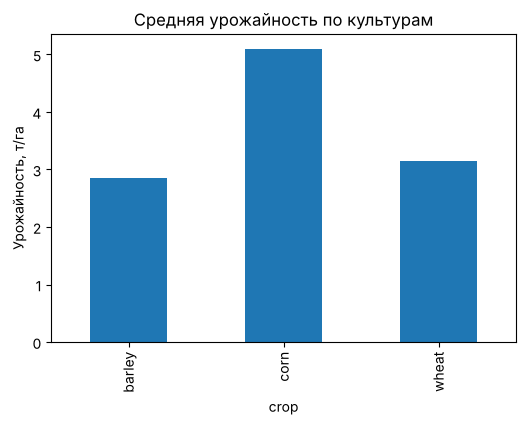

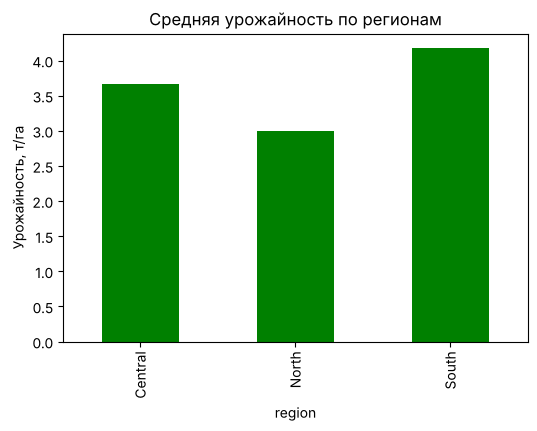

In [18]:
avg_by_crop = df_yield.groupby("crop")["yield_t_per_ha"].mean()
plt.figure(figsize=(6, 4))
avg_by_crop.plot(kind="bar")
plt.ylabel("Урожайность, т/га")
plt.title("Средняя урожайность по культурам")
plt.show()

avg_by_region = df_yield.groupby("region")["yield_t_per_ha"].mean()
plt.figure(figsize=(6, 4))
avg_by_region.plot(kind="bar", color="green")
plt.ylabel("Урожайность, т/га")
plt.title("Средняя урожайность по регионам")
plt.show()

## 9. Вопросы для самопроверки

1. Чем отличается `df["col"]` от `df[["col"]]`?
2. Как выбрать строки, где урожайность больше 3.0 и регион `South`?
3. В чём разница между `groupby` и `pivot_table`?
4. Чем отличается `inner` от `left` при объединении таблиц?
5. Почему для категориальных признаков часто используют one-hot кодирование?

### Ответы

**1.** `df["col"]` возвращает один столбец в виде Series, то есть одномерный набор значений с индексом. `df[["col"]]` возвращает DataFrame, то есть таблицу из одного столбца. Видно по заданию 2: `crops` это Series, а `year_yield` это DataFrame.

**2.** Нужно объединить два условия через `&`, каждое условие в своих скобках:

```python
df_yield[(df_yield["yield_t_per_ha"] > 3.0) & (df_yield["region"] == "South")]
```

Или то же самое через query: `df_yield.query("yield_t_per_ha > 3.0 and region == 'South'")`. Обычные `and` и `or` с масками не работают, нужны `&` и `|`.

**3.** `groupby` разбивает таблицу на группы и считает по ним значение (среднее, сумму и т.д.). Результат получается «длинным»: каждая группа это отдельная строка, как в `avg_by_year_crop`. `pivot_table` делает то же самое, но раскладывает результат в виде таблицы: один признак идет по строкам, другой по столбцам. Такую таблицу удобнее читать, когда группировка идет сразу по двум признакам.

**4.** `inner` оставляет только те строки, у которых ключ есть в обеих таблицах. `left` оставляет все строки левой таблицы, а если в правой таблице пары нет, на этом месте будет NaN. В задании 11 у поля 102 нет данных об удобрениях: при left join оно осталось с NaN, а при inner join его бы не было в результате.

**5.** Потому что label кодирование присваивает категориям числа, и модель начинает считать, что между ними есть порядок и расстояние (например, что chestnut = 1 находится «между» chernozem = 0 и sod-podzolic = 2), хотя на самом деле типы почвы просто разные. При one-hot кодировании каждая категория становится отдельным столбцом из 0 и 1, и никакого ложного порядка нет. Минус в том, что при большом числе категорий получается много столбцов.